# ThemeSync — Results Analysis

Consultation-ready summary of the real, measured results collected so far
against the manuscript's own 4-phase Research Procedure (Chapter 3, pp. 50-58).
Numbers are loaded from actual artifacts in the repo, so re-running this
notebook after a new pipeline run or YOLO retrain refreshes it. **One
exception:** the per-class v2/v3 table is copied from the training console
logs, because Ultralytics doesn't write per-class metrics to `results.csv`.
The v3/v4 per-class numbers come from `results/yolo_v4_experiment.json`
(validation runs).

**Sources used:**
- `runs/yolo/themesync_layout_yolo/results.csv`: Stage 0b YOLOv8, CGL-Dataset pretrain (`themesync_yolo_v1.pt`)
- `runs/yolo/themesync_master_layout_finetune/results.csv`: 65-image real-poster fine-tune (`themesync_yolo_v2.pt`)
- `runs/yolo/themesync_master_layout_finetune_v3/results.csv`: 124-image real-poster fine-tune, continued from v2 (`themesync_yolo_v3.pt`)
- `results/yolo_domain_gap_check.json`: v1/v2/v3 on 3 unseen real posters (`src/evaluation/yolo_domain_gap_check.py`)
- `results/yolo_v4_experiment.json`: v3 vs. v4 (YOLOv8s, 1024 px, cleaned labels) on the same validation labels
- `results/yolo_v5_comparison.json`: v4 vs. the deployed v5 (the group's 200-image re-annotation) on validation images neither trained on (`src/evaluation/yolo_compare.py`)
- `results/gnn_heldout_eval.json`: GNN v1 / v2 / v3 on 2,900 held-out CGL layouts, plus the exact-anchor test (`src/evaluation/gnn_heldout_eval.py`)
- `results/experiment_log.json`: Phase 3 battery, 15 real master layouts × 2 formats × 3 Stage 2 conditions (`src/evaluation/experiment_runner.py`)
- `results/evaluation_results.json`: synthetic certificate comparison plus simulated designer edits (`src/evaluation/evaluate.py`)
- Phase 4 (MOS / expert validation): **no real data yet**; placeholder at the bottom

Full narrative/evidence behind every number: `notes/gnn_fixes_and_methodology_notes.md`
(§3.6-3.7, §3.12, §3.25 and §3.30 for YOLO; §3.22 and §3.26 for the GNN; §3.23, §3.27 and §3.29 for the current Phase 3 setup).

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent  # allow running from notebooks/ or repo root

# Validated categorical palette (dataviz skill reference palette -- fixed order,
# never cycled; slots 1/2 clear the adjacent-pair CVD/contrast gates together).
SERIES_1 = "#2a78d6"   # blue   -- v1 / GNN-guided / "before"
SERIES_2 = "#eb6834"   # orange -- v2 / Baseline / "after"
SERIES_3 = "#1baf7a"   # aqua   -- third series when needed
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID = "#e3e2dd"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "text.color": TEXT_PRIMARY,
    "axes.labelcolor": TEXT_SECONDARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "font.size": 10,
})


## Phase 1 -- YOLOv8 Layout Parser: CGL Pretrain -> v2 (65 img) -> v3 (124 img) -> v4 -> v5 (deployed)

`themesync_yolo_v1.pt` was trained on the public CGL-Dataset. `themesync_yolo_v2.pt`
fine-tuned it on 65 real, hand-annotated CSPC SSC poster images. `themesync_yolo_v3.pt`
continues from v2 on an expanded 124-image batch (the original 65 plus 59 more).
v1's validation set (CGL's own held-out split) isn't comparable to v2/v3's (this
project's own real-poster held-out split), so v1 gets its own chart; v2 and v3
share a held-out methodology and are directly comparable, so they're overlaid.


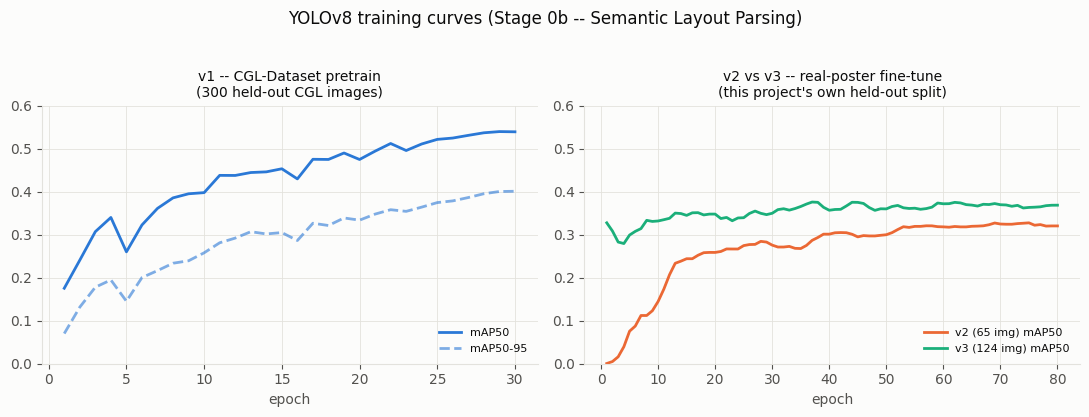

In [2]:
v1 = pd.read_csv(ROOT / "runs/yolo/themesync_layout_yolo/results.csv")
v2 = pd.read_csv(ROOT / "runs/yolo/themesync_master_layout_finetune/results.csv")
v3 = pd.read_csv(ROOT / "runs/yolo/themesync_master_layout_finetune_v3/results.csv")
v1.columns = [c.strip() for c in v1.columns]
v2.columns = [c.strip() for c in v2.columns]
v3.columns = [c.strip() for c in v3.columns]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(v1["epoch"], v1["metrics/mAP50(B)"], color=SERIES_1, linewidth=2, label="mAP50")
axes[0].plot(v1["epoch"], v1["metrics/mAP50-95(B)"], color=SERIES_1, linewidth=2,
             linestyle="--", alpha=0.6, label="mAP50-95")
axes[0].set_title("v1 -- CGL-Dataset pretrain\n(300 held-out CGL images)", fontsize=10)

for df, label, color in [(v2, "v2 (65 img)", SERIES_2), (v3, "v3 (124 img)", SERIES_3)]:
    axes[1].plot(df["epoch"], df["metrics/mAP50(B)"], color=color, linewidth=2, label=f"{label} mAP50")
axes[1].set_title("v2 vs v3 -- real-poster fine-tune\n(this project's own held-out split)", fontsize=10)

for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_ylim(0, 0.6)
    ax.legend(frameon=False, fontsize=8, loc="lower right")

fig.suptitle("YOLOv8 training curves (Stage 0b -- Semantic Layout Parsing)", y=1.03)
fig.tight_layout()
plt.show()


In [3]:
summary = pd.DataFrame([
    {
        "model": "v1 (CGL pretrain)",
        "val_set": "300 CGL held-out images / 1448 instances",
        "precision": v1["metrics/precision(B)"].iloc[-1],
        "recall": v1["metrics/recall(B)"].iloc[-1],
        "mAP50": v1["metrics/mAP50(B)"].iloc[-1],
        "mAP50-95": v1["metrics/mAP50-95(B)"].iloc[-1],
    },
    {
        "model": "v2 (65-image real-poster fine-tune)",
        "val_set": "15 held-out real posters",
        "precision": v2["metrics/precision(B)"].iloc[-1],
        "recall": v2["metrics/recall(B)"].iloc[-1],
        "mAP50": v2["metrics/mAP50(B)"].iloc[-1],
        "mAP50-95": v2["metrics/mAP50-95(B)"].iloc[-1],
    },
    {
        "model": "v3 (124-image real-poster fine-tune)",
        "val_set": "25 held-out real posters",
        "precision": v3["metrics/precision(B)"].iloc[-1],
        "recall": v3["metrics/recall(B)"].iloc[-1],
        "mAP50": v3["metrics/mAP50(B)"].iloc[-1],
        "mAP50-95": v3["metrics/mAP50-95(B)"].iloc[-1],
    },
]).set_index("model")
summary.round(3)


,val_set,precision,recall,mAP50,mAP50-95
model,,,,,
v1 (CGL pretrain),300 CGL held-out images / 1448 instances,0.580,0.478,0.539,0.401
v2 (65-image real-poster fine-tune),15 held-out real posters,0.627,0.304,0.320,0.183
v3 (124-image real-poster fine-tune),25 held-out real posters,0.459,0.349,0.368,0.212


### A real data-quality catch, before v3 existed

Checking the newly-uploaded 124-image export before training on it found two
real problems, confirmed with an actual test run rather than assumed: (1)
~23% of the images were being silently dropped during training because their
label files mixed plain bounding-box rows with polygon rows -- Ultralytics
discards the whole file rather than partially using it; (2) the class index
order had shifted between exports (alphabetized in the new one), which would
have silently scrambled what v2's checkpoint had already learned if fine-tuned
on as-is. Both fixed (polygons converted to their enclosing boxes, indices
remapped) and re-verified (0 corrupt files) before the retrain below ran. Full
detail: `notes/gnn_fixes_and_methodology_notes.md` Section 3.12.


### Per-class breakdown: v2 vs v3

Not in `results.csv` (Ultralytics only logs aggregate metrics there) -- pulled
from the console output captured in `notes/gnn_fixes_and_methodology_notes.md`
Sections 3.7 (v2) and 3.12 (v3). **`underlay` is still weak** (44 validation
instances now, up from 17 -- better, not yet enough to learn well);
**`embellishment` stayed flat** despite the batch nearly doubling (consistent
with the group's decision not to prioritize hunting for these); `logo` and
`text` -- the two structurally important classes -- both improved meaningfully.


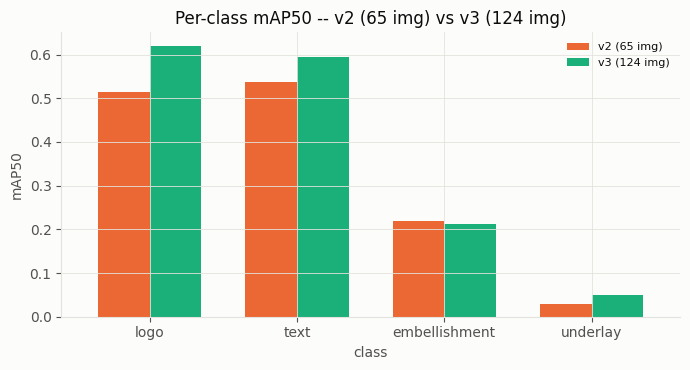

,v2_mAP50,v3_mAP50
class,,
logo,0.5150,0.6200
text,0.5380,0.5950
embellishment,0.2180,0.2130
underlay,0.0288,0.0499


In [4]:
per_class = pd.DataFrame([
    {"class": "logo",          "v2_mAP50": 0.515,  "v3_mAP50": 0.620},
    {"class": "text",          "v2_mAP50": 0.538,  "v3_mAP50": 0.595},
    {"class": "embellishment", "v2_mAP50": 0.218,  "v3_mAP50": 0.213},
    {"class": "underlay",      "v2_mAP50": 0.0288, "v3_mAP50": 0.0499},
]).set_index("class")

ax = per_class.plot(kind="bar", color=[SERIES_2, SERIES_3], figsize=(7, 3.8), width=0.7)
ax.set_ylabel("mAP50")
ax.set_title("Per-class mAP50 -- v2 (65 img) vs v3 (124 img)")
ax.set_xticklabels(per_class.index, rotation=0)
ax.legend(["v2 (65 img)", "v3 (124 img)"], frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

per_class


### Real-domain generalization check (v1 -> v2 -> v3, same 3 posters)

Top detection confidence, and the number of detections usable at conf >= 0.25,
on 3 CSPC posters outside the original 65-image annotation batch: a test of
whether fine-tuning closed the CGL-to-real-poster domain gap rather than
memorizing training examples. (`YOUR_TEMPLATE2.jpg`, YUGTO 2026, is left out on
purpose: it was in every fine-tune's training data.)

**Caveat, found 2026-09-28:** TAN-AW was later added to the 124-image batch, so
it *is* in v3's training data (detected automatically by image hash; it was
renamed by Roboflow). Its v3 bars are hatched below and don't count as
generalization. The clean v3 evidence is La Serata and LODT, which no model
has trained on.

Re-measured 2026-09-28 with `src/evaluation/yolo_domain_gap_check.py`. The v2
values match the earlier measurement (0.74 / 0.73 / 0.69). The v1 values replace
hand-typed ones (0.20 / 0.46 / 0.31) that previously sat in this cell and didn't
match any saved measurement; the re-measured v1 La Serata value (0.035) matches
the original v1 log in notes §3.5.

**How to read v2 vs v3 here:** v3 is more confident on all three posters, but
finds fewer usable detections on two of them (La Serata 16 -> 10, TAN-AW 13 ->
9; LODT 8 -> 11). These posters have no hand-drawn ground truth, so this check
can't tell whether the drop means fewer false positives or more misses. It
shows the domain gap *stays closed*; accuracy comes from the held-out mAP table
above (v3 0.370 vs v2 0.320).

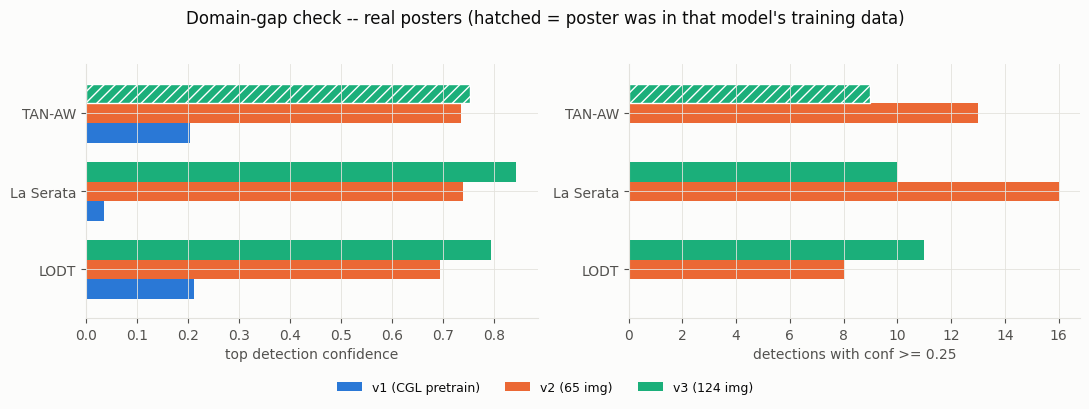

top_conf               usable_detections            
model           v1     v2     v3                v1    v2    v3
poster                                                        
LODT         0.211  0.694  0.793               0.0   8.0  11.0
La Serata    0.035  0.740  0.843               0.0  16.0  10.0
TAN-AW       0.204  0.735  0.753               0.0  13.0   9.0

In [5]:
with open(ROOT / "results/yolo_domain_gap_check.json") as f:
    gap = json.load(f)

gap_rows = []
for version, per_poster in gap["results"].items():
    for poster, m in per_poster.items():
        gap_rows.append({"poster": poster, "model": version,
                         "top_conf": m["top_conf"], "usable_detections": m["n_ge_025"]})
gap_df = pd.DataFrame(gap_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric, label in [(axes[0], "top_conf", "top detection confidence"),
                          (axes[1], "usable_detections", "detections with conf >= 0.25")]:
    gap_df.pivot(index="poster", columns="model", values=metric)[["v1", "v2", "v3"]].plot(
        kind="barh", ax=ax, color=[SERIES_1, SERIES_2, SERIES_3], width=0.75)
    ax.set_xlabel(label)
    ax.set_ylabel("")
    ax.get_legend().remove()
    # Hatch any bar whose poster was in that checkpoint's training data.
    posters = list(gap_df.pivot(index="poster", columns="model", values=metric).index)
    for container, version in zip(ax.containers, ["v1", "v2", "v3"]):
        for bar, poster in zip(container, posters):
            if gap["seen_in_training"][version][poster]:
                bar.set_hatch("///")
                bar.set_edgecolor("white")
fig.legend(["v1 (CGL pretrain)", "v2 (65 img)", "v3 (124 img)"], loc="lower center",
           ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Domain-gap check -- real posters (hatched = poster was in that model's training data)", y=1.02)
fig.tight_layout()
plt.show()

gap_df.pivot(index="poster", columns="model", values=["top_conf", "usable_detections"])

### v3 vs. v4 on the same cleaned validation labels (notes §3.25)

Why detection was weak on master layouts: partly the labels (60 boxes cover
more than half their poster; `embellishment` mixes sparkles with mascots),
mostly the model and its input size (YOLOv8n at 640 px, where a poster's
logo row is a few dozen pixels high). v4 is YOLOv8s from COCO weights at
1024 px, trained on the 124-image batch with the over-half boxes removed.
Both are scored on the same cleaned validation labels.

**Reading it:** logos and text improve most (logo mAP50 0.62 → 0.82, recall
0.55 → 0.76): the capacity and resolution fix. Embellishment doesn't move
(recall 0.17 → 0.18): a class-definition problem no model size fixes, which
is why the group re-annotated the batch (`notes/annotation_guidelines.md`). v4 changed size, resolution,
initialisation and labels together; v5 (below), trained with v4's exact
recipe on the group's re-annotation, isolates the labels' share.

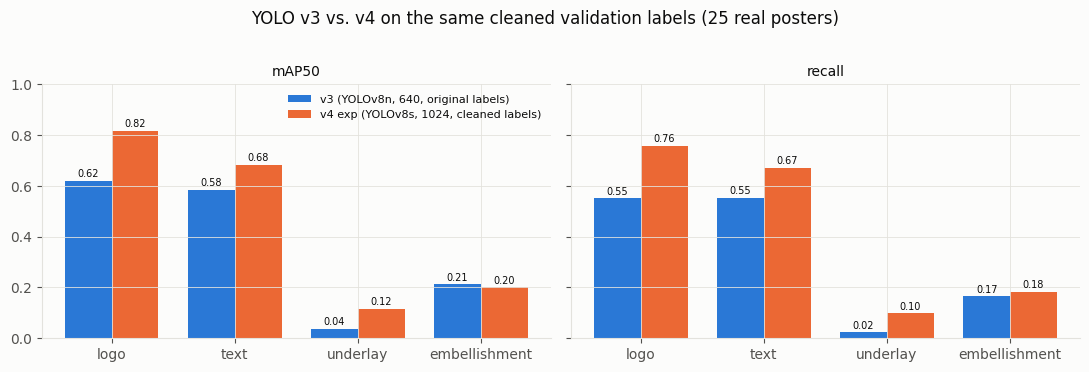

,mAP50,mAP50-95,precision,recall
v3,0.363,0.213,0.526,0.324
v4 exp,0.454,0.300,0.562,0.427


In [6]:
with open(ROOT / "results/yolo_v4_experiment.json") as f:
    yolo4 = json.load(f)
runs = {k: v for k, v in yolo4.items() if isinstance(v, dict)}
labels = {k: k.split(" (")[0] for k in runs}          # "v3", "v4 exp"
classes = list(next(iter(runs.values()))["per_class_mAP50"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
width = 0.38
for ax, metric, title in [(axes[0], "per_class_mAP50", "mAP50"), (axes[1], "per_class_recall", "recall")]:
    for j, (name, run) in enumerate(runs.items()):
        vals = [run[metric][c] for c in classes]
        xs = [k + (j - 0.5) * width for k in range(len(classes))]
        ax.bar(xs, vals, width=width, color=[SERIES_1, SERIES_2][j], label=name)
        for x, v in zip(xs, vals):
            ax.text(x, v + 0.015, f"{v:.2f}", ha="center", fontsize=7, color=TEXT_PRIMARY)
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, 1)
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("YOLO v3 vs. v4 on the same cleaned validation labels (25 real posters)", y=1.02)
plt.tight_layout()
plt.show()

pd.DataFrame({labels[k]: {"mAP50": r["mAP50"], "mAP50-95": r["mAP50-95"], "precision": r["precision"],
                          "recall": r["recall"]} for k, r in runs.items()}).T

### v4 vs. v5: the group's 200-image re-annotation (notes §3.30)

v5 is v4's exact recipe (YOLOv8s from COCO, 1024 px, AMP, seed 0) trained on
the group's re-annotation of **200** master layouts (160 train / 40
validation). The export kept the 4 classes; its polygon rows were converted
to boxes first (`prepare_master_layout_dataset.py`). Both models are scored
on the new validation labels, each at its own image size and in its own
class order, leaving out every image either model trained on: 7 v4 trained
on, and HIRAYA, which sits in both of v5's splits. 32 images remain. 25 of
them were v4's own validation images, which picked its best checkpoint, so
if anything v4 is flattered.

**Reading it:** the re-annotation fixed what model size couldn't.
Embellishment recall goes 0.21 → 0.51 and underlay 0.10 → 0.52; logo
mAP50 reaches 0.98. Part of the gain is v5 having learned the new labelling
conventions the validation labels also follow, but logo and embellishment
improve on any reading. **v5 is the deployed detector.**

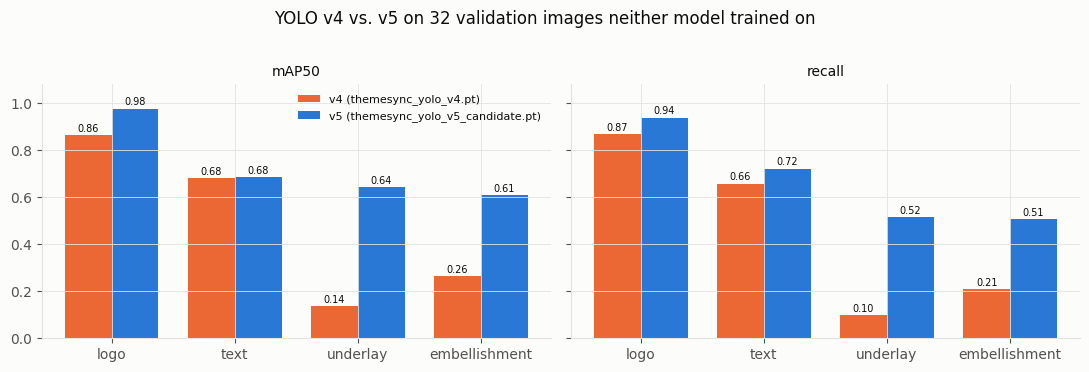

,mAP50,mAP50-95,precision,recall
v4,0.486,0.311,0.580,0.458
v5,0.728,0.496,0.841,0.671


In [7]:
with open(ROOT / "results/yolo_v5_comparison.json") as f:
    yolo5 = json.load(f)
classes = ["logo", "text", "underlay", "embellishment"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
width = 0.38
for ax, metric in [(axes[0], "mAP50"), (axes[1], "recall")]:
    for j, (name, m) in enumerate(yolo5["models"].items()):
        vals = [m["per_class"][c][metric] for c in classes]
        xs = [k + (j - 0.5) * width for k in range(len(classes))]
        ax.bar(xs, vals, width=width, color=[SERIES_2, SERIES_1][j], label=f"{name} ({m['checkpoint']})")
        for x, v in zip(xs, vals):
            ax.text(x, v + 0.015, f"{v:.2f}", ha="center", fontsize=7, color=TEXT_PRIMARY)
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_title(metric, fontsize=10)
    ax.set_ylim(0, 1.08)
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle(f"YOLO v4 vs. v5 on {yolo5['val_images']} validation images neither model trained on", y=1.02)
plt.tight_layout()
plt.show()

pd.DataFrame({k: {"mAP50": m["mAP50"], "mAP50-95": m["mAP50-95"], "precision": m["precision"],
                  "recall": m["recall"]} for k, m in yolo5["models"].items()}).T

## Phase 1 -- GNN: v1 as deployed, v2, and v3 (held-out CGL layouts)

v1 was trained with each CGL layout's *true* positions as input, but at
inference every node started at (0, 0). v2 starts training and inference
from the same naive stack and learns designers' real positions and spacing
(notes §3.22). **v3** (the default) is trained from two starts per layout:
the naive stack (no master) and the layout's own structure distorted the
way a cross-format mapping distorts it, which is what Stage 2 feeds it from
a real master layout (notes §3.26). Every row is scored on the same 2,900
held-out CGL layouts (a seeded 5% of CGL train; CGL's own test split has no
annotations), each model fed the input it receives in the pipeline. Lower
is better for both errors (fractions of the canvas).

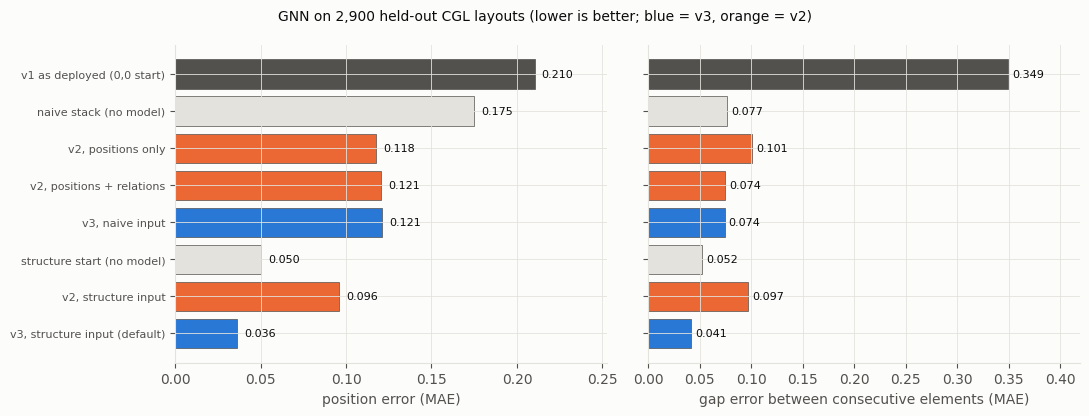

,mae_xy,mae_gap,order_kept,overlap
"v1 as deployed (0,0 start)",0.2104,0.3494,0.4717,0.0020
naive stack (no model),0.1750,0.0766,1.0000,0.0000
"v2, positions only",0.1176,0.1007,0.9981,0.0000
"v2, positions + relations",0.1207,0.0741,0.9986,0.0000
"v3, naive input",0.1212,0.0739,0.9991,0.0000
structure start (no model),0.0503,0.0517,0.9812,0.0044
"v2, structure input",0.0961,0.0969,0.9236,0.0037
"v3, structure input (default)",0.0364,0.0411,0.9708,0.0005


In [8]:
with open(ROOT / "results/gnn_heldout_eval.json") as f:
    gnn_eval = json.load(f)

gnn_df = pd.DataFrame(gnn_eval["results"]).T[["mae_xy", "mae_gap", "order_kept", "overlap"]]
def colour(name):
    if name.startswith("v1"):
        return TEXT_SECONDARY
    if "no model" in name:
        return GRID
    return SERIES_2 if name.startswith("v2") else SERIES_1
colors = [colour(n) for n in gnn_df.index]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, metric, label in [(axes[0], "mae_xy", "position error (MAE)"),
                          (axes[1], "mae_gap", "gap error between consecutive elements (MAE)")]:
    vals = gnn_df[metric]
    ax.barh(range(len(vals)), vals, color=colors, edgecolor=TEXT_SECONDARY, linewidth=0.5)
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels(vals.index if ax is axes[0] else [""] * len(vals), fontsize=8)
    ax.invert_yaxis()
    for i, v in enumerate(vals):
        ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8, color=TEXT_PRIMARY)
    ax.set_xlabel(label)
    ax.set_xlim(0, vals.max() * 1.2)
fig.suptitle(f"GNN on {gnn_eval['heldout_layouts']:,} held-out CGL layouts (lower is better; "
             "blue = v3, orange = v2)", fontsize=10)
plt.tight_layout()
plt.show()

gnn_df.round(4)

**Reading it:** v1 was worse than using no model at all. From the naive
stack, v2 and v3 are equally good (position error 0.121 vs. 0.175 for the
stack itself). From a master's structure, v3 cuts the structure start's
position error by 28% (0.036 vs. 0.050), its gap error by 20% and its
overlap by 89%; v2, never trained on such a start, makes it worse (0.096).

### What Stage 2 needs on a real master: keep the anchors, place the rest

On a real master the mapped anchors aren't noise: they are the composition
being transferred. So each held-out layout is anchored at its **real**
centres, with up to half its elements left unmapped (placed by
interpolation), and the error is split into anchored and unmapped
elements. Raw v3, trained only on distorted starts, still "corrects" the
anchors (2.6% of the height) and places the unmapped elements no better
than interpolation. Registered to the anchors
(`graph_builder.register_to_anchors`, what Stage 2 now does), it keeps them
exactly and places the unmapped elements 8% better than interpolation.
v2 registered is worse than interpolation: v3's structure training is what
earns the gain.

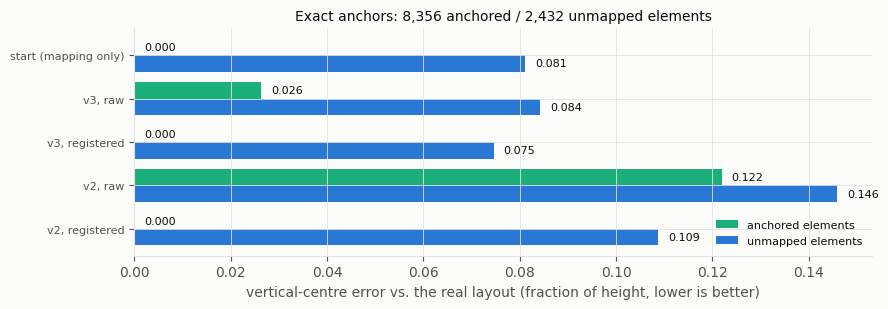

,anchored,unmapped,all
start (mapping only),0.0000,0.0812,0.0183
"v3, raw",0.0264,0.0843,0.0395
"v3, registered",0.0000,0.0746,0.0168
"v2, raw",0.1219,0.1459,0.1273
"v2, registered",0.0000,0.1088,0.0245


In [9]:
exact = pd.DataFrame(gnn_eval["exact_anchors"]["results"]).T[["anchored", "unmapped", "all"]]
fig, ax = plt.subplots(figsize=(9, 3.2))
width = 0.38
for j, (col, colr) in enumerate([("anchored", SERIES_3), ("unmapped", SERIES_1)]):
    ys = [k + (j - 0.5) * width for k in range(len(exact))]
    ax.barh(ys, exact[col], height=width, color=colr, label=f"{col} elements")
    for y, v in zip(ys, exact[col]):
        ax.text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=8, color=TEXT_PRIMARY)
ax.set_yticks(range(len(exact)))
ax.set_yticklabels(exact.index, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("vertical-centre error vs. the real layout (fraction of height, lower is better)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title(f"Exact anchors: {gnn_eval['exact_anchors']['anchored_elements']:,} anchored / "
             f"{gnn_eval['exact_anchors']['unmapped_elements']:,} unmapped elements", fontsize=10)
plt.tight_layout()
plt.show()

exact.round(4)

## Phase 3 -- Stage 2 conditions on real master layouts

Re-run 2026-10-06 on the current system (notes §3.25-3.30): YOLO v5, the
GNN v3 with its output registered to the master's anchors, six candidates
per run that differ in layout archetype (classic, left-aligned, art column,
banner, floating card, full-width band) as well as margin, rhythm and motif
arrangement, and seeded colour clustering (§3.29; earlier runs carried
palette noise). The battery runs the full pipeline (the same
`OrchestrationSession` the dashboard uses) on the **16 unseen Phase 4 event
posters** (the group's new set), for each format, under three Stage 2 conditions: **GNN-guided**
(the master's mapped structure, refined by the GNN), **mapping only** (the
mapped structure, no GNN: the ablation) and the **baseline** (no structure,
no GNN). 96 runs. Each master is one trial: the pipeline is deterministic
per input.

Besides the fitness terms, each run records its **structure error**: how
far the output's anchored elements (logo row and header on certificates;
also title and details on the event ID) sit vertically from their
counterparts on the master, as a fraction of the height. It is reported
for the winner and averaged over all six candidates, because certificate
candidates often tie on C_total and the winner then reflects the ranking's
tie-break more than Stage 2.

In [10]:
with open(ROOT / "results/experiment_log.json") as f:
    exp = json.load(f)

METHODS = [("GNN-guided", "gnn_trials"), ("Mapping only", "mapping_trials"), ("Baseline", "base_trials")]
rows = []
for domain, dd in exp["results"].items():
    for method, key in METHODS:
        for t in dd.get(key, []):
            rows.append({
                "format": dd["domain_label"], "method": method, "poster": t["poster"],
                "C_total": t["C_total"], "P_collision": t["P_collision"], "P_align": t["P_align"],
                "P_space": t["P_space"], "P_legibility": t["P_legibility"],
                "structure_error": t.get("structure_error"), "structure_error_all": t.get("structure_error_all"),
                "winner": t["winner"], "latency_ms": t["latency_total"],
            })
trials_df = pd.DataFrame(rows)
order = {m: k for k, (m, _) in enumerate(METHODS)}

penalties = (trials_df.groupby(["format", "method"])
             [["C_total", "P_collision", "P_align", "P_space", "P_legibility", "structure_error",
               "structure_error_all", "latency_ms"]]
             .agg(["mean", "std"]).round(4))
penalties = penalties.iloc[sorted(range(len(penalties)), key=lambda k: (penalties.index[k][0],
                                                                         order[penalties.index[k][1]]))]
penalties

C_total         P_collision       \
                                           mean     std        mean  std   
format                     method                                          
Academic Certificate (4:3) GNN-guided    0.0020  0.0022         0.0  0.0   
                           Mapping only  0.0020  0.0022         0.0  0.0   
                           Baseline      0.0021  0.0024         0.0  0.0   
Event ID (A6, 1:1.414)     GNN-guided    0.1492  0.0120         0.0  0.0   
                           Mapping only  0.1480  0.0109         0.0  0.0   
                           Baseline      0.1456  0.0082         0.0  0.0   

                                        P_align      P_space          \
                                           mean  std    mean     std   
format                     method                                      
Academic Certificate (4:3) GNN-guided       0.0  0.0  0.0014  0.0008   
                           Mapping only     0.0  0.0  0.0014  0.0008   
                           Baseline         0.0  0.0  0.0014  0.0008   
Event ID (A6, 1:1.414)     GNN-guided       0.0  0.0  0.1383  0.0000   
                           Mapping only     0.0  0.0  0.1383  0.0000   
                           Baseline         0.0  0.0  0.1383  0.0000   

                                        P_legibility         structure_error  \
                                                mean     std            mean   
format                     method                                              
Academic Certificate (4:3) GNN-guided         0.0004  0.0015          0.0585   
                           Mapping only       0.0004  0.0015          0.0585   
                           Baseline           0.0004  0.0016          0.0905   
Event ID (A6, 1:1.414)     GNN-guided         0.0072  0.0080          0.0526   
                           Mapping only       0.0064  0.0073          0.0526   
                           Baseline           0.0048  0.0055          0.1184   

                                                structure_error_all          \
                                            std                mean     std   
format                     method                                             
Academic Certificate (4:3) GNN-guided    0.0387              0.0564  0.0319   
                           Mapping only  0.0387              0.0564  0.0319   
                           Baseline      0.0353              0.0887  0.0357   
Event ID (A6, 1:1.414)     GNN-guided    0.0390              0.0451  0.0362   
                           Mapping only  0.0390              0.0451  0.0362   
                           Baseline      0.0458              0.1171  0.0460   

                                        latency_ms             
                                              mean        std  
format                     method                              
Academic Certificate (4:3) GNN-guided    5924.0525  2453.6422  
                           Mapping only  5874.8956  2458.6557  
                           Baseline      5899.5969  2391.7402  
Event ID (A6, 1:1.414)     GNN-guided    5234.6825  2341.0241  
                           Mapping only  5219.8944  2355.5743  
                           Baseline      5248.6269  2385.7292

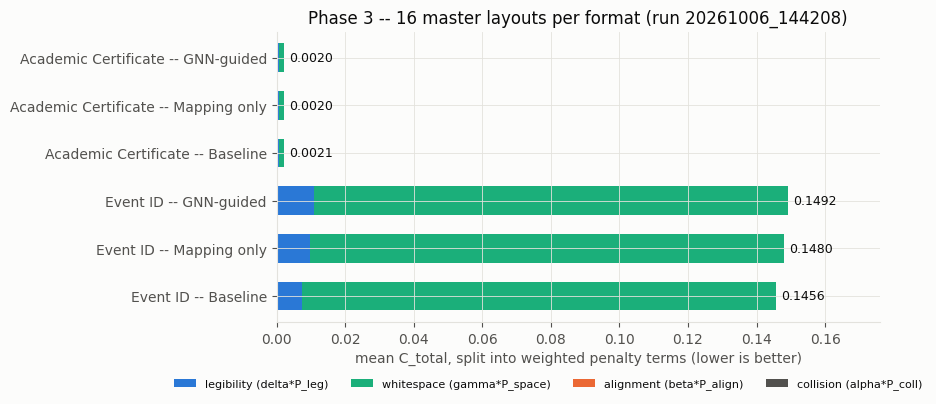

,legibility (delta*P_leg),whitespace (gamma*P_space),alignment (beta*P_align),collision (alpha*P_coll),C_total
Academic Certificate -- GNN-guided,0.0006,0.0014,0.0,0.0,0.0020
Academic Certificate -- Mapping only,0.0006,0.0014,0.0,0.0,0.0020
Academic Certificate -- Baseline,0.0006,0.0014,0.0,0.0,0.0021
Event ID -- GNN-guided,0.0108,0.1383,0.0,0.0,0.1492
Event ID -- Mapping only,0.0097,0.1383,0.0,0.0,0.1480
Event ID -- Baseline,0.0073,0.1383,0.0,0.0,0.1456


In [11]:
import sys
sys.path.insert(0, str(ROOT / "src" / "solvers"))
from optimization_engine import HeuristicEvaluator

# Split each mean C_total into its weighted Formula 3.11 terms, using the
# evaluator's own weights.
w = HeuristicEvaluator()
means = trials_df.groupby(["format", "method"])[["C_total", "P_collision", "P_align", "P_space", "P_legibility"]].mean()
means = means.iloc[sorted(range(len(means)), key=lambda k: (means.index[k][0], order[means.index[k][1]]))]
parts = pd.DataFrame({
    "legibility (delta*P_leg)": w.delta * means["P_legibility"],
    "whitespace (gamma*P_space)": w.gamma * means["P_space"],
    "alignment (beta*P_align)": w.beta * means["P_align"],
    "collision (alpha*P_coll)": w.alpha * means["P_collision"],
})
parts.index = [f"{fmt.split(' (')[0]} -- {method}" for fmt, method in parts.index]
fig, ax = plt.subplots(figsize=(9, 4.2))
parts.plot(kind="barh", stacked=True, ax=ax, color=[SERIES_1, SERIES_3, SERIES_2, TEXT_SECONDARY], width=0.6)
for i, total in enumerate(means["C_total"]):
    ax.text(total + means["C_total"].max() * 0.01, i, f"{total:.4f}", va="center", fontsize=9, color=TEXT_PRIMARY)
ax.invert_yaxis()
ax.set_xlabel("mean C_total, split into weighted penalty terms (lower is better)")
ax.set_ylabel("")
ax.set_xlim(0, means["C_total"].max() * 1.18)
ax.set_title(f"Phase 3 -- {exp['config']['masters']} master layouts per format (run {exp['run_id']})")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.16), ncol=4)
plt.tight_layout()
plt.show()

parts.assign(C_total=means["C_total"].values).round(4)

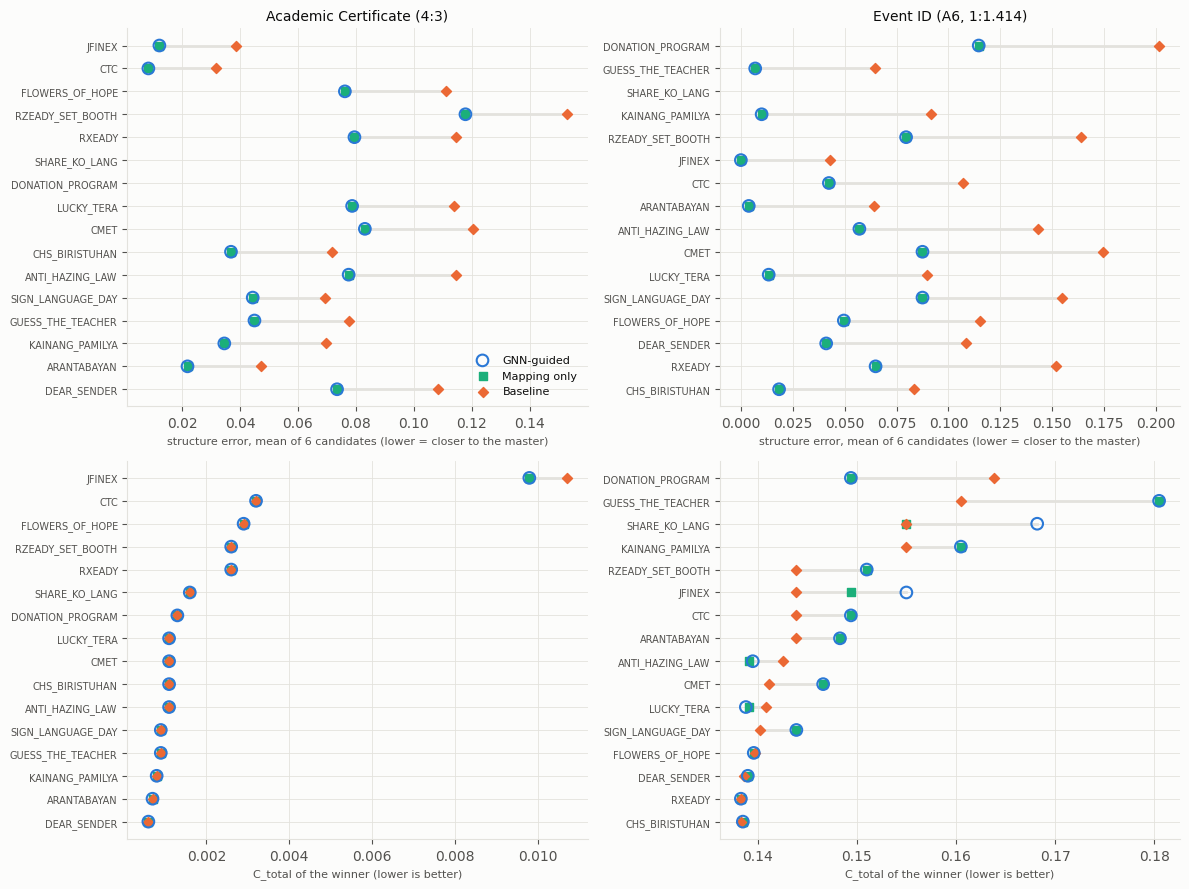

In [12]:
# Per master: structure error (all six candidates) and C_total, for each condition.
# GNN is drawn as a ring: it coincides with mapping on 29 of 30 runs.
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
marks = {"GNN-guided": (SERIES_1, "o"), "Mapping only": (SERIES_3, "s"), "Baseline": (SERIES_2, "D")}
for col, (domain, dd) in enumerate(exp["results"].items()):
    trials = {m: {t["poster"]: t for t in dd.get(k, [])} for m, k in METHODS}
    posters = sorted(trials["Baseline"], key=lambda p: trials["Baseline"][p]["C_total"])
    for row, (metric, label) in enumerate([("structure_error_all", "structure error, mean of 6 candidates (lower = closer to the master)"),
                                            ("C_total", "C_total of the winner (lower is better)")]):
        ax = axes[row][col]
        for y, p in enumerate(posters):
            vals = [trials[m][p].get(metric) for m in marks if p in trials[m]]
            vals = [v for v in vals if v is not None]
            if vals:
                ax.plot([min(vals), max(vals)], [y, y], color=GRID, linewidth=2, zorder=1)
            for m, (c, mk) in marks.items():
                v = trials[m].get(p, {}).get(metric)
                if v is None:
                    continue
                if m == "GNN-guided":   # a ring on top, so it shows where it coincides with mapping
                    ax.scatter(v, y, facecolors="none", edgecolors=c, marker=mk, s=70, linewidths=1.5,
                               zorder=4, label=m if y == 0 else None)
                else:
                    ax.scatter(v, y, color=c, marker=mk, s=26, zorder=3, label=m if y == 0 else None)
        ax.set_yticks(range(len(posters)))
        ax.set_yticklabels([p.rsplit(".", 1)[0] for p in posters], fontsize=7)
        ax.set_xlabel(label, fontsize=8)
        if row == 0:
            ax.set_title(dd["domain_label"], fontsize=10)
axes[0][0].legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Reading this run (16 unseen master layouts per format, 96 runs, YOLO v5):**

- **The master's structure reaches the output.** The GNN-guided output is
  closer to the master than the baseline on 15 of 16 event IDs (structure
  error 0.045 vs. 0.117, well under half the distance) and on 14 of 16
  certificates (0.056 vs. 0.089). The rest have no roles to map: SHARE KO
  LANG's script title isn't detected as a title, and on DONATION PROGRAM the
  organisation name printed beside the logos was merged into the title
  group, so nothing sits above the "title" (a certificate maps only the
  logo row and header).
- **Formula 3.11 doesn't reward it.** Certificates tie on 15 of 16. On
  event IDs the baseline scores slightly better (C_total 0.1456 vs.
  0.1492; GNN lower on 4, equal on 1, higher on 11), through legibility:
  following a poster's composition puts text where the poster had its
  artwork. Nothing in the fitness function measures "keeps the master's
  composition", which is what Phase 4's MOS judges (visual hierarchy
  preservation, brand consistency).
- **GNN vs. mapping only:** the same anchor positions everywhere, and the
  same winner and fitness on 28 of 32 runs. The GNN moves the unmapped
  elements (name, role, the certificate's lower block) on 13 of 32 runs, by
  up to 7.6% of the height. Both formats are tall stacks with little
  vertical slack, so once the master's anchors are placed the solver's
  design rules leave little to decide. The GNN's gain over interpolation is
  shown on held-out data above, not in these scores.
- The previous run (2026-09-29: YOLO v4, the earlier 15 posters) showed the
  same pattern; it is kept as `results/experiment_log_20260929_old15_v4.json`.
- **Latency** is about 3-12 s per full run on the shared server; the GNN
  itself takes ~50 ms.

In [13]:
with open(ROOT / "results/evaluation_results.json") as f:
    ev = json.load(f)

fixed_rows = []
for method, trials in [("GNN-guided", ev["gnn_guided"]), ("Baseline", ev["baseline"])]:
    for t in trials:
        f1 = t["constraint_f1"]
        fixed_rows.append({
            "method": method,
            "mean_iou": t["mean_iou"],
            "C_total": t["heuristic_fitness"]["C_total"],
            "hard_nodes_kept": f"{f1['hard_preserved']}/{f1['total_hard']}",
            "retention_f1": f1["f1"],
            "collision_after_edits": f1.get("collision_after_edits"),
            "latency_ms": t["timings_ms"]["total_ms"],
        })
fixed_df = pd.DataFrame(fixed_rows).set_index("method")
print("Simulated designer events:", ev["gnn_guided"][0]["constraint_f1"].get("events"))
fixed_df

Simulated designer events: ['Moved {{Issuing_Organization}}', 'Resized {{Presentation_Line}}', 'Locked {{Certificate_ID}}']


,mean_iou,C_total,hard_nodes_kept,retention_f1,collision_after_edits,latency_ms
method,,,,,,
GNN-guided,0.2559,1.1256,3/3,1.0,0.0,1015.37
Baseline,NaN,1.1256,3/3,1.0,0.0,473.88


**Synthetic certificate (no master layout) plus simulated designer edits.**
With the synthetic theme there is no background to score legibility
against, so GNN and baseline tie on C_total (1.1256), consistent with the
battery above. The second part is the manuscript's "non-destructive
retention of manual user refinements" (p.54): three designer events are
simulated — a move (on-drop), a resize (on-resize-complete) and a lock — and
after the solver re-flows the other nodes, every Hard node must still sit
exactly where the designer left it (1 px tolerance). All three are kept, with
no overlap introduced, in both modes. `tests/test_certificate_pipeline.py`
checks the same property on every run (`test_hard_constraints_preserved`).

## Phase 4 -- Expert Aesthetic Validation (MOS)

**No real data yet.** `src/evaluation/mos_collector.py` is built and, as of
2026-09-26, matches the manuscript's instrument (pp. 57-58): the 3 named
parameters (Visual Hierarchy Preservation, Brand and Typographic
Consistency, Constraint and Whitespace Harmony), Table 2's rating scale shown
to the evaluator, and layouts presented in randomized order. But
`results/mos_results.json` doesn't exist yet: no domain expert has rated any
output. This section is intentionally left as a placeholder rather than
filled with synthetic numbers. Re-run this notebook once a real MOS session
has been collected and this cell will pick the data up automatically.


In [14]:
mos_path = ROOT / "results" / "mos_results.json"
if mos_path.exists():
    with open(mos_path) as f:
        mos = json.load(f)
    print(f"{len(mos.get('evaluations', []))} real MOS evaluation(s) found -- rerun analysis below.")
else:
    print("No results/mos_results.json yet -- Phase 4 has zero real evaluator data as of this run.")


No results/mos_results.json yet -- Phase 4 has zero real evaluator data as of this run.
